# Dataset validation: FISTA3D ToMoBAR on GEANT4 dataset 1

Reconstruct `geant4_dataset1.npz` and compare numerical checks with the saved slice,
region of interest and line profile.

## Data and execution

Use `geant4_dataset1.npz` from [Zenodo record 17252190](https://zenodo.org/records/17252190).
The repository downloader verifies the archive checksums.
Run from the repository root:

```bash
python .scripts/download_zenodo.py Zenodo
python -m pip install -e '.[validation]'
python -m pytest --nbmake --nbmake-timeout=1800 --overwrite docs/source/validation/reconstruction/regularised/fista3d_geant4_dataset1.ipynb
```

Use an NVIDIA GPU with compatible CuPy and ToMoBAR installed, plus ASTRA for
ASTRA-based reconstruction. Run notebooks serially. Set `HTTOMOLIBGPU_DATA_DIR`
to use an archive stored elsewhere.

Documentation builds render saved outputs without running GPU computations.
Execute with `--overwrite` before building documentation to update the results.


In [1]:
import gc
import math
import pytest
import hashlib
import json
import os
import platform
from importlib.metadata import version
from pathlib import Path

import cupy as cp
import matplotlib.pyplot as plt
import numpy as np
from numpy.testing import assert_allclose

from httomolibgpu.prep.normalize import dark_flat_field_correction, minus_log
from httomolibgpu.recon.algorithm import FISTA3d_tomobar

# Locate the checkout from either the repository root or the notebook directory.
repo_root = next(
    (
        p
        for p in (Path.cwd(), *Path.cwd().parents)
        if (p / "pyproject.toml").is_file() and (p / "httomolibgpu").is_dir()
    ),
    None,
)
data_dir = os.environ.get("HTTOMOLIBGPU_DATA_DIR")
if data_dir is None:
    if repo_root is None:
        raise FileNotFoundError(
            "Set HTTOMOLIBGPU_DATA_DIR to the Zenodo archive directory"
        )
    data_dir = repo_root / "Zenodo"
data_path = Path(data_dir).expanduser() / "geant4_dataset1.npz"
if not data_path.is_file():
    raise FileNotFoundError(
        f"Missing {data_path}; run .scripts/download_zenodo.py first"
    )

checksum = hashlib.sha256()
with data_path.open("rb") as stream:
    for chunk in iter(lambda: stream.read(1024 * 1024), b""):
        checksum.update(chunk)
props = cp.cuda.runtime.getDeviceProperties(cp.cuda.Device().id)
provenance = {
    "dataset": data_path.name,
    "zenodo_record": "17252190",
    "sha256": checksum.hexdigest(),
    "python": platform.python_version(),
    "packages": {
        name: version(name)
        for name in ("httomolibgpu", "tomobar", "astra-toolbox", "numpy")
    },
    "cupy": cp.__version__,
    "cuda_runtime": cp.cuda.runtime.runtimeGetVersion(),
    "cuda_driver": cp.cuda.runtime.driverGetVersion(),
    "gpu": (
        props["name"].decode() if isinstance(props["name"], bytes) else props["name"]
    ),
}
print(json.dumps(provenance, indent=2))

{
  "dataset": "geant4_dataset1.npz",
  "zenodo_record": "17252190",
  "sha256": "e5d891184671c45d7d5502cad94a5a0ac7e1adf94d7ffc93bc26637e8e0b7daa",
  "python": "3.14.7",
  "packages": {
    "httomolibgpu": "6.0.1.post16+git.bbaa03d2.dirty",
    "tomobar": "2026.3.1.0",
    "astra-toolbox": "2.5.0",
    "numpy": "2.4.6"
  },
  "cupy": "14.2.0",
  "cuda_runtime": 13020,
  "cuda_driver": 13020,
  "gpu": "NVIDIA GeForce RTX 4060"
}


## Preprocessing

Input axes are `(angle, detector row, detector column)`.
Select detector rows `268:273` consistently from projections, flats and darks
before default dark/flat correction and `minus_log`. Use all 360 angles in
radians and centre 319.5 pixels. References apply to these five simulated rows.


Reconstruction input: (360, 5, 640)


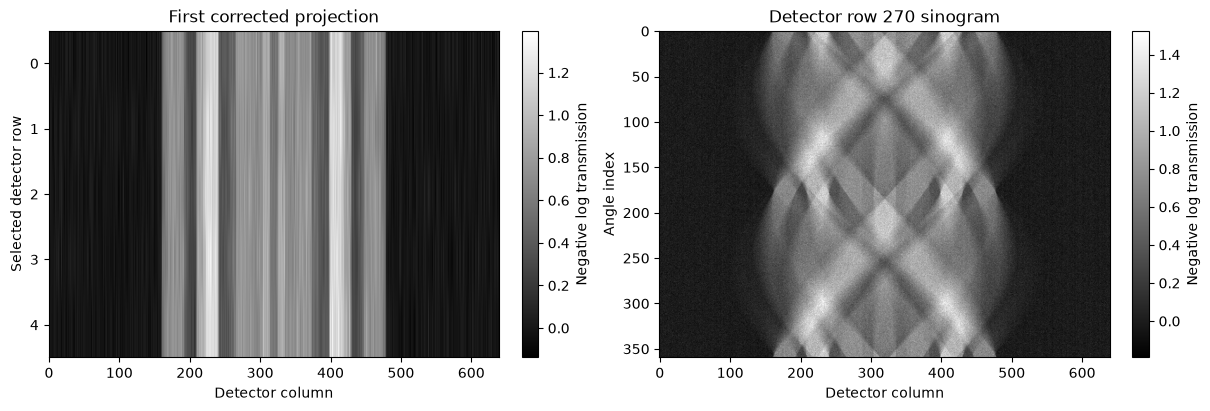

In [2]:
row_selection = slice(268, 273)
with np.load(data_path) as archive:
    projdata = cp.asarray(archive["projdata"][:, row_selection, :])
    flats = cp.asarray(archive["flats"][:, row_selection, :])
    darks = cp.asarray(archive["darks"][:, row_selection, :])
    angles = archive["angles"].copy()
assert projdata.shape == (360, 5, 640)
reconstruction_input = minus_log(dark_flat_field_correction(projdata, flats, darks))
del projdata, flats, darks
gc.collect()
cp.get_default_memory_pool().free_all_blocks()
recon_angles = np.deg2rad(angles)
assert reconstruction_input.shape[0] == len(recon_angles)
assert bool(cp.isfinite(reconstruction_input).all())
print("Reconstruction input:", reconstruction_input.shape)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, image, title, ylabel in (
    (
        axes[0],
        reconstruction_input[0].get(),
        "First corrected projection",
        "Selected detector row",
    ),
    (
        axes[1],
        reconstruction_input[:, 2, :].get(),
        "Detector row 270 sinogram",
        "Angle index",
    ),
):
    im = ax.imshow(image, cmap="gray", aspect="auto")
    ax.set(title=title, xlabel="Detector column", ylabel=ylabel)
    fig.colorbar(im, ax=ax, label="Negative log transmission")
plt.show()
plt.close(fig)

## Reconstruction and regression assertions

Use 7 FISTA iterations with 6 ordered subsets, LS fidelity, automatic
detector padding and PD-TV strength `1e-05`. Each outer iteration
visits all subsets; half-precision regularisation and nonnegativity are enabled.
Output axes are `(Y, detector row, X)`. Numerical assertions run after plotting.


In [3]:
parameters = {
    "center": 319.5,
    "detector_pad": True,
    "recon_mask_radius": 2.0,
    "iterations": 7,
    "subsets_number": 6,
    "data_fidelity": "LS",
    "regularisation_type": "PD_TV",
    "regularisation_parameter": 1e-5,
    "regularisation_iterations": 50,
    "regularisation_half_precision": True,
    "nonnegativity": True,
}
print("Reconstruction parameters:", parameters)
recon_gpu = FISTA3d_tomobar(reconstruction_input, recon_angles, **parameters)
assert isinstance(recon_gpu, cp.ndarray)
assert recon_gpu.flags.c_contiguous
assert recon_gpu.dtype == cp.float32
assert recon_gpu.shape == (640, 5, 640)
assert bool(cp.isfinite(recon_gpu).all()), "Non-finite reconstruction"
assert bool((recon_gpu >= 0).all()), "Nonnegativity constraint violated"
recon_data = cp.asnumpy(recon_gpu)
del recon_gpu, reconstruction_input
gc.collect()
cp.get_default_memory_pool().free_all_blocks()
observed_mean = float(recon_data.mean(dtype=np.float64))
observed_max = float(recon_data.max())
observed_min = float(recon_data.min())
print(
    json.dumps(
        {
            "shape": list(recon_data.shape),
            "dtype": str(recon_data.dtype),
            "mean": observed_mean,
            "maximum": observed_max,
            "minimum": observed_min,
            "sum_float64": float(recon_data.sum(dtype=np.float64)),
        },
        indent=2,
    )
)
print("Structural and nonnegativity checks passed.")

Reconstruction parameters: {'center': 319.5, 'detector_pad': True, 'recon_mask_radius': 2.0, 'iterations': 7, 'subsets_number': 6, 'data_fidelity': 'LS', 'regularisation_type': 'PD_TV', 'regularisation_parameter': 1e-05, 'regularisation_iterations': 50, 'regularisation_half_precision': True, 'nonnegativity': True}


{
  "shape": [
    640,
    5,
    640
  ],
  "dtype": "float32",
  "mean": 0.0005438686530962648,
  "maximum": 0.005848458502441645,
  "minimum": 0.0,
  "sum_float64": 1113.8430015411502
}
Structural and nonnegativity checks passed.


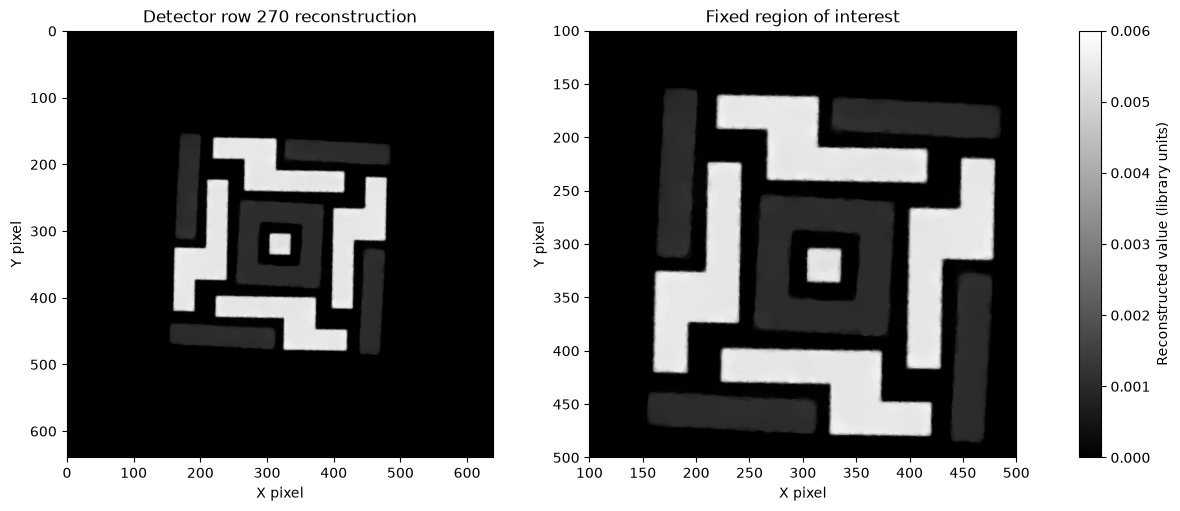

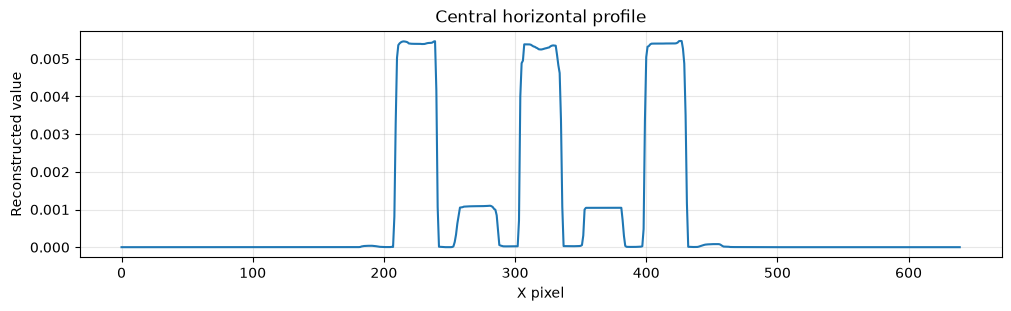

In [4]:
image = recon_data[:, 2, :]
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
limits = {"vmin": 0, "vmax": 0.006, "cmap": "gray"}
im = axes[0].imshow(image, **limits)
axes[0].set(title="Detector row 270 reconstruction", xlabel="X pixel", ylabel="Y pixel")
axes[1].imshow(image[100:500, 100:500], extent=(100, 500, 500, 100), **limits)
axes[1].set(title="Fixed region of interest", xlabel="X pixel", ylabel="Y pixel")
fig.colorbar(im, ax=axes, label="Reconstructed value (library units)")
plt.show()
plt.close(fig)
fig, ax = plt.subplots(figsize=(10, 3), constrained_layout=True)
ax.plot(image[image.shape[0] // 2, :])
ax.set(
    title="Central horizontal profile", xlabel="X pixel", ylabel="Reconstructed value"
)
ax.grid(alpha=0.3)
plt.show()
plt.close(fig)

In [5]:
# GEANT4 quantitative reference: detector rows 268:273, settings above.
expected_mean = 0.0005438686530962648
expected_max = 0.005848458502441645
expected_min = 0.0
assert_allclose(
    observed_mean, expected_mean, rtol=1e-3, atol=1e-8, err_msg="Mean changed"
)
assert_allclose(
    observed_max, expected_max, rtol=1e-3, atol=1e-8, err_msg="Maximum changed"
)
assert_allclose(
    observed_min, expected_min, rtol=1e-3, atol=1e-8, err_msg="Minimum changed"
)
print("All regression checks passed.")

del recon_data, image
gc.collect()
cp.get_default_memory_pool().free_all_blocks()
cp.get_default_pinned_memory_pool().free_all_blocks()

All regression checks passed.
